<a href="https://colab.research.google.com/github/ingsisdianaf-collab/MACHINE-LEARNING/blob/main/ML_No_Supervisado_Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Paso 1 .Importación de librerías
Para desarrollar este ejercicio de aprendizaje no supervisado se utilizarán diferentes librerías de Python que permiten organizar, procesar y visualizar los datos. NumPy y Pandas facilitan el manejo de la información, mientras que Matplotlib permite representar gráficamente los resultados.Por otra parte, Scikit-learn proporciona los algoritmos K-means, clustering jerárquico, PCA y SVD. También se utiliza SciPy para construir el dendrograma del agrupamiento jerárquico.Estas herramientas permitirán comparar las técnicas y analizar cómo identifican patrones o reducen la dimensionalidad de los datos.

In [ ]:
# PASO 1. Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

print("Librerías importadas correctamente")


Librerías importadas correctamente


PASO 2. Carga y exploración del conjunto de datos Wine
Para este ejercicio se seleccionó el conjunto de datos Wine, disponible en la biblioteca Scikit-learn. Este conjunto contiene 178 muestras de vino y 13 características numéricas relacionadas con su composición química.

Se eligió porque permite aplicar diferentes técnicas de aprendizaje no supervisado sobre un mismo conjunto de datos. Esto facilita identificar agrupaciones, estudiar las relaciones entre las variables y analizar la reducción de dimensionalidad.

En esta etapa se revisará la estructura de los datos, sus dimensiones, los nombres de las variables y los primeros registros. Aunque el conjunto incluye categorías de referencia, estas no se utilizarán para entrenar los algoritmos no supervisados.

In [ ]:
# PASO 2. Carga y exploración de los datos

wine = load_wine()

# Crear un DataFrame con las características
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

print("Dimensiones del conjunto de datos:")
print(df.shape)

print("\nNombres de las variables:")
print(df.columns.tolist())

print("\nPrimeros cinco registros:")
display(df.head())

print("\nInformación general:")
df.info()

print("\nValores faltantes por variable:")
print(df.isnull().sum())

Dimensiones del conjunto de datos:
(178, 13)

Nombres de las variables:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Primeros cinco registros:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

PASO 3. Estandarización de los datos
Después de revisar el conjunto de datos Wine, se identificó que las 13 variables son numéricas y no presentan valores faltantes. Sin embargo, sus valores se encuentran en diferentes escalas, por lo que es necesario estandarizarlos antes de aplicar los algoritmos.

Para este procedimiento se utiliza StandardScaler de Scikit-learn, que transforma cada característica para que tenga una media cercana a cero y una desviación estándar cercana a uno.

Esta transformación es importante porque los algoritmos de agrupamiento basados en distancias pueden dar mayor importancia a las variables con valores numéricos más altos. La estandarización permite realizar una comparación más equilibrada entre las características del conjunto de datos.

In [ ]:
# PASO 3. Estandarización de los datos

# Crear el objeto para estandarizar
scaler = StandardScaler()

# Aplicar la estandarización
X_scaled = scaler.fit_transform(df)

# Convertir el resultado en un DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

print("Datos estandarizados correctamente")

print("\nPrimeros cinco registros:")
display(df_scaled.head())

print("\nMedia de las variables:")
print(df_scaled.mean().round(4))

print("\nDesviación estándar:")
print(df_scaled.std(ddof=0).round(4))

Datos estandarizados correctamente

Primeros cinco registros:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874



Media de las variables:
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Desviación estándar:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                         1.0
dt

PASO 4. Aplicación del algoritmo K-means
K-means es un algoritmo de aprendizaje no supervisado que permite agrupar observaciones de acuerdo con sus características. Su funcionamiento consiste en asignar cada registro al centroide más cercano y actualizar estos centros hasta alcanzar una solución estable.

En este ejercicio se utilizarán las 13 características estandarizadas del conjunto Wine para identificar grupos de vinos con propiedades químicas similares.

Antes de establecer la cantidad de grupos, se aplicarán el método del codo y el coeficiente de silueta. El método del codo permite observar cómo disminuye la inercia al aumentar el número de grupos, mientras que el coeficiente de silueta ayuda a evaluar qué tan compactos y separados se encuentran.

Esta comparación permitirá justificar la selección del número de grupos a partir de los resultados obtenidos y no únicamente de una decisión previa.

,Número de grupos,Inercia,Silueta
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.4283,0.2602
3,5,1109.5127,0.2016
4,6,1046.0023,0.2372
5,7,981.5952,0.2036
6,8,935.2012,0.1570
7,9,889.8929,0.1499
8,10,845.8952,0.1436


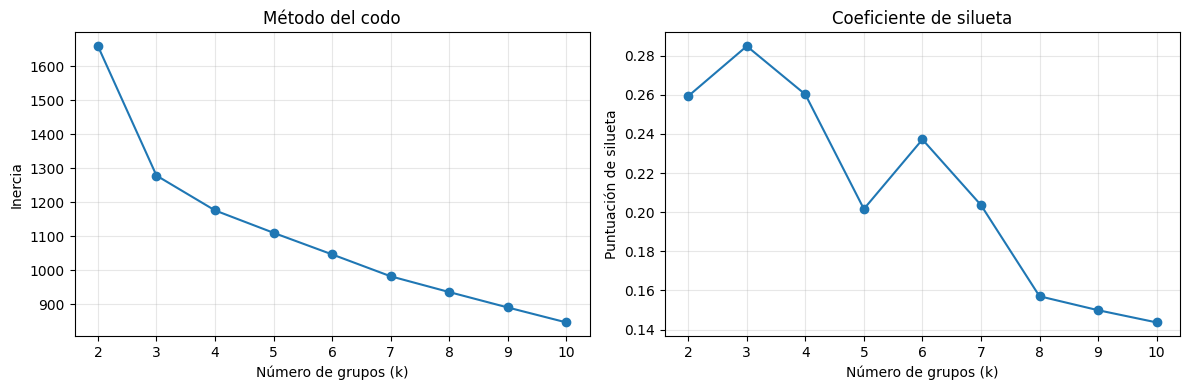

Número de grupos con mayor silueta: 3


In [ ]:
# PASO 4. Evaluación del número de grupos con K-means

valores_k = range(2, 11)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    inercias.append(modelo.inertia_)
    siluetas.append(
        silhouette_score(X_scaled, etiquetas)
    )

# Mostrar los resultados numéricos
resultados_k = pd.DataFrame({
    "Número de grupos": list(valores_k),
    "Inercia": inercias,
    "Silueta": siluetas
})

display(resultados_k.round(4))

# Graficar método del codo y silueta
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(
    list(valores_k), inercias,
    marker="o"
)
ax[0].set_title("Método del codo")
ax[0].set_xlabel("Número de grupos (k)")
ax[0].set_ylabel("Inercia")
ax[0].grid(alpha=0.3)

ax[1].plot(
    list(valores_k), siluetas,
    marker="o"
)
ax[1].set_title("Coeficiente de silueta")
ax[1].set_xlabel("Número de grupos (k)")
ax[1].set_ylabel("Puntuación de silueta")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "paso4_evaluacion_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

mejor_k = list(valores_k)[np.argmax(siluetas)]

print(
    "Número de grupos con mayor silueta:",
    mejor_k
)


PASO 5. Entrenamiento y visualización del algoritmo K-means
Después de evaluar diferentes cantidades de grupos mediante el método del codo y el coeficiente de silueta, se seleccionaron tres grupos para aplicar el algoritmo K-means. Esta decisión se tomó porque el valor más alto de silueta fue aproximadamente 0,285, correspondiente a tres agrupaciones.

En este paso se entrena el modelo utilizando las 13 características estandarizadas del conjunto Wine. El algoritmo asigna cada muestra al grupo cuyo centroide se encuentra más cercano, buscando que los elementos de un mismo grupo tengan características similares.

Para representar los resultados en una gráfica de dos dimensiones se utiliza PCA. Esta técnica permite proyectar los datos sobre dos componentes principales y facilita observar cómo quedaron distribuidos los grupos. Es importante aclarar que K-means se entrena con las 13 variables y que PCA se utiliza aquí únicamente para visualizar los resultados.

Cantidad de vinos por grupo:
0    65
1    51
2    62
Name: count, dtype: int64

Inercia del modelo:
1277.9285

Coeficiente de silueta:
0.2849


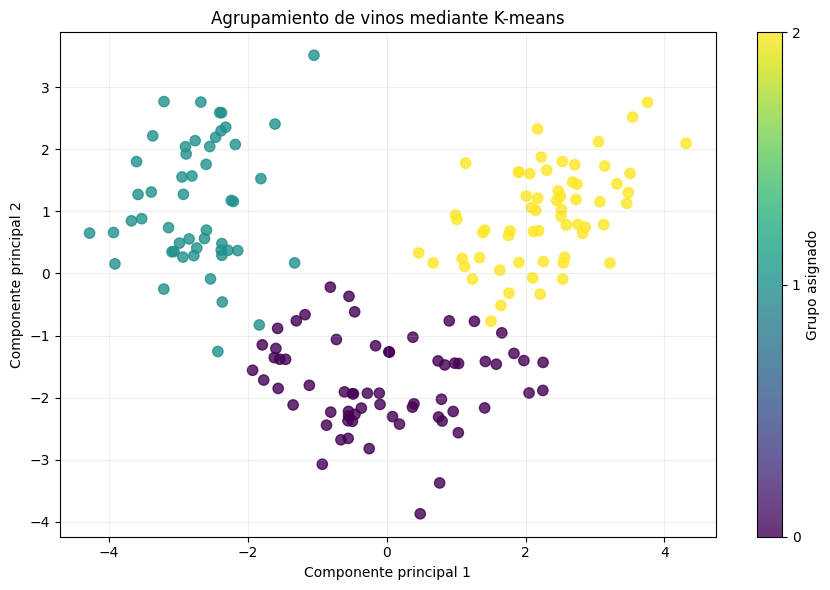

In [ ]:
# PASO 5. Entrenamiento y visualización de K-means

# Entrenar K-means con tres grupos
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

grupos_kmeans = kmeans.fit_predict(X_scaled)

# Contar los registros de cada grupo
conteo_grupos = pd.Series(
    grupos_kmeans
).value_counts().sort_index()

print("Cantidad de vinos por grupo:")
print(conteo_grupos)

print("\nInercia del modelo:")
print(round(kmeans.inertia_, 4))

print("\nCoeficiente de silueta:")
print(round(
    silhouette_score(X_scaled, grupos_kmeans),
    4
))

# Reducir a dos dimensiones para visualizar
pca_visual = PCA(n_components=2)
X_pca_visual = pca_visual.fit_transform(X_scaled)

# Crear gráfica
plt.figure(figsize=(9, 6))

grafica = plt.scatter(
    X_pca_visual[:, 0],
    X_pca_visual[:, 1],
    c=grupos_kmeans,
    cmap="viridis",
    s=55,
    alpha=0.8
)

plt.title("Agrupamiento de vinos mediante K-means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.colorbar(
    grafica,
    ticks=[0, 1, 2],
    label="Grupo asignado"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "paso5_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


PASO 6. Aplicación del clustering jerárquico
El clustering jerárquico es una técnica de aprendizaje no supervisado que permite identificar grupos de observaciones a partir de sus semejanzas. A diferencia de K-means, este método construye una estructura de agrupaciones que puede representarse mediante un dendrograma.

Para este ejercicio se utilizará el método de Ward, que busca formar agrupaciones procurando minimizar el aumento de la variabilidad interna al unir grupos.

Se trabajará con las 13 características estandarizadas del conjunto Wine. El dendrograma permitirá observar cómo se relacionan las muestras y a qué distancias se producen las uniones entre los grupos.

Posteriormente, estos resultados servirán para comparar el comportamiento del clustering jerárquico con el algoritmo K-means.

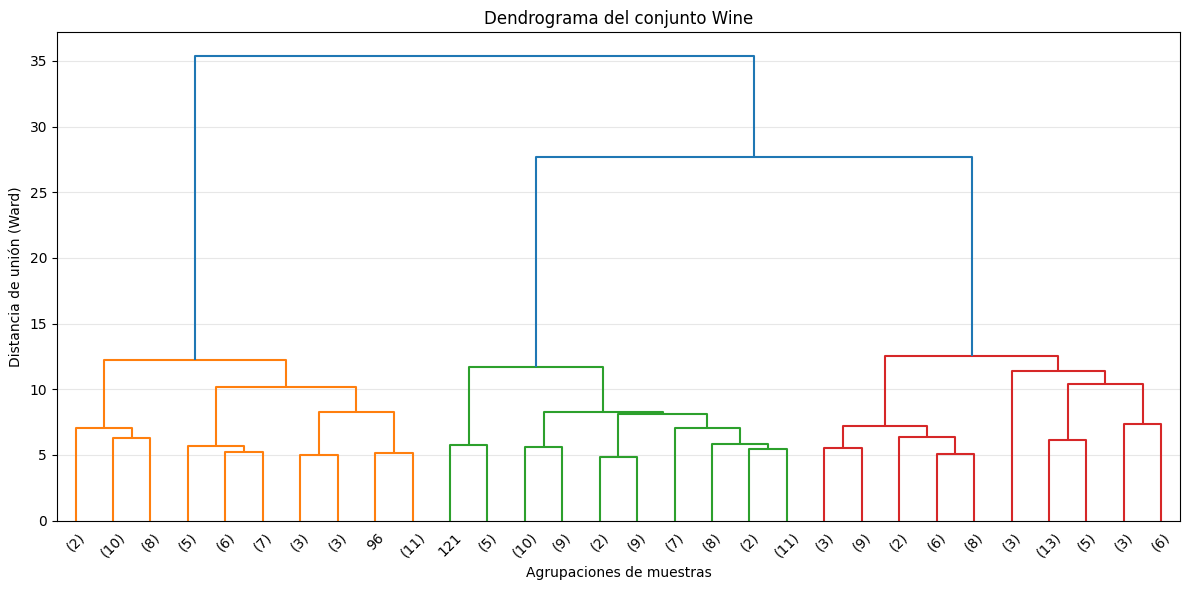

Dendrograma generado correctamente


In [ ]:
# PASO 6. Clustering jerárquico con método Ward

# Construir la estructura jerárquica
matriz_enlace = linkage(
    X_scaled,
    method="ward"
)

# Crear el dendrograma
plt.figure(figsize=(12, 6))

dendrogram(
    matriz_enlace,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Dendrograma del conjunto Wine")
plt.xlabel("Agrupaciones de muestras")
plt.ylabel("Distancia de unión (Ward)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "paso6_dendrograma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dendrograma generado correctamente")

PASO 7. Evaluación y comparación de los algoritmos de agrupamiento
Después de aplicar K-means y construir el dendrograma del clustering jerárquico, se realizará una comparación entre los dos métodos. Para mantener las mismas condiciones, ambos algoritmos trabajarán con las 13 características estandarizadas del conjunto Wine y se utilizarán tres grupos.

La comparación se realizará mediante el coeficiente de silueta, que permite evaluar qué tan similares son las observaciones dentro de cada grupo y qué tan diferentes son respecto a los demás grupos.

También se revisará la cantidad de vinos asignados a cada agrupación. Con estos resultados se podrá identificar cuál de los dos métodos presenta una mejor separación de los grupos, sin asumir que uno de ellos es superior en todos los casos.

Comparación de algoritmos:


,Algoritmo,Número de grupos,Coeficiente de silueta
0,K-means,3,0.2849
1,Jerárquico,3,0.2774



Cantidad de vinos por grupo jerárquico:
0    58
1    56
2    64
Name: count, dtype: int64


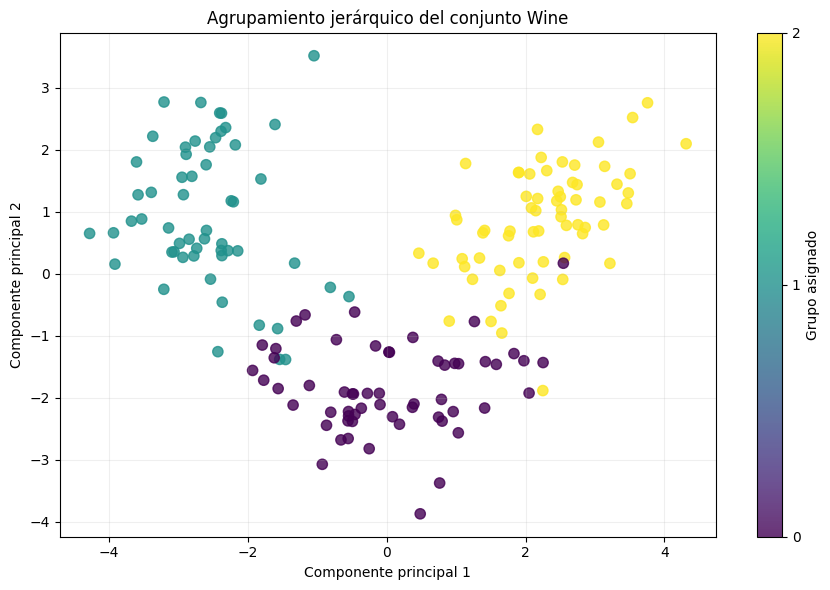


Método con mayor coeficiente de silueta: K-means


In [ ]:
# PASO 7. Comparación K-means y clustering jerárquico

# Aplicar clustering jerárquico con tres grupos
jerarquico = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

grupos_jerarquico = jerarquico.fit_predict(X_scaled)

# Calcular los coeficientes de silueta
silueta_kmeans = silhouette_score(
    X_scaled, grupos_kmeans
)

silueta_jerarquico = silhouette_score(
    X_scaled, grupos_jerarquico
)

# Crear tabla comparativa
comparacion = pd.DataFrame({
    "Algoritmo": ["K-means", "Jerárquico"],
    "Número de grupos": [3, 3],
    "Coeficiente de silueta": [
        silueta_kmeans,
        silueta_jerarquico
    ]
})

print("Comparación de algoritmos:")
display(comparacion.round(4))

print("\nCantidad de vinos por grupo jerárquico:")
print(pd.Series(grupos_jerarquico).value_counts().sort_index())

# Visualizar los resultados del clustering jerárquico
plt.figure(figsize=(9, 6))

grafica = plt.scatter(
    X_pca_visual[:, 0],
    X_pca_visual[:, 1],
    c=grupos_jerarquico,
    cmap="viridis",
    s=55,
    alpha=0.8
)

plt.title("Agrupamiento jerárquico del conjunto Wine")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.colorbar(
    grafica,
    ticks=[0, 1, 2],
    label="Grupo asignado"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "paso7_clustering_jerarquico.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identificar el método con mayor silueta
mejor_metodo = comparacion.loc[
    comparacion["Coeficiente de silueta"].idxmax(),
    "Algoritmo"
]

print("\nMétodo con mayor coeficiente de silueta:", mejor_metodo)


PASO 8. Reducción de dimensionalidad mediante PCA
El análisis de componentes principales (PCA) es una técnica que permite reducir la cantidad de variables de un conjunto de datos, procurando conservar la mayor parte posible de su variabilidad.

En este ejercicio se aplica PCA a las 13 características estandarizadas del conjunto Wine, con el propósito de representarlas mediante dos componentes principales. Estos componentes son nuevas variables construidas a partir de combinaciones de las características originales.

La reducción facilita la visualización de los datos y permite observar su distribución en un espacio de dos dimensiones. Sin embargo, es importante comprobar qué porcentaje de la varianza original se conserva, ya que reducir las dimensiones también puede ocasionar pérdida de información.

Dimensiones originales: (178, 13)
Dimensiones después de PCA: (178, 2)

Primeros cinco registros transformados:


,Componente principal 1,Componente principal 2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831



Varianza explicada por cada componente:
[36.2  19.21]

Varianza total conservada:
55.41 %


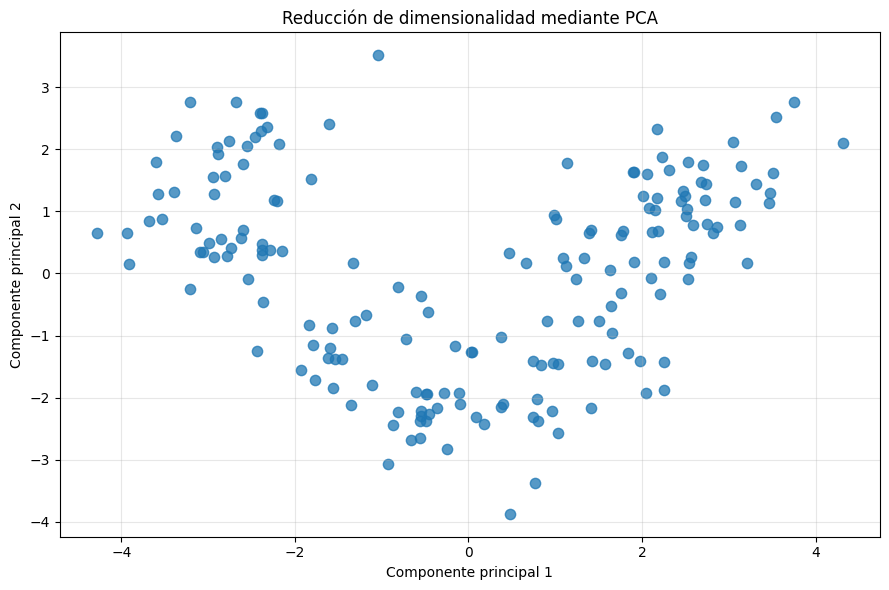

In [ ]:
# PASO 8. Reducción de dimensionalidad con PCA

# Aplicar PCA con dos componentes principales
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Crear tabla con los datos reducidos
df_pca = pd.DataFrame(
    X_pca,
    columns=[
        "Componente principal 1",
        "Componente principal 2"
    ]
)

print("Dimensiones originales:", X_scaled.shape)
print("Dimensiones después de PCA:", X_pca.shape)

print("\nPrimeros cinco registros transformados:")
display(df_pca.head())

# Calcular varianza explicada
varianza_pca = pca.explained_variance_ratio_

print("\nVarianza explicada por cada componente:")
print(np.round(varianza_pca * 100, 2))

print("\nVarianza total conservada:")
print(round(sum(varianza_pca) * 100, 2), "%")

# Visualizar los datos transformados
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=55,
    alpha=0.75
)

plt.title("Reducción de dimensionalidad mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "paso8_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


PASO 9. Análisis de la varianza explicada por PCA
Después de reducir las 13 características del conjunto Wine a dos componentes principales, es necesario analizar qué porcentaje de la variabilidad de los datos se conserva con esta transformación.

Para ello, se aplicará PCA utilizando los 13 componentes disponibles y se calculará la varianza explicada por cada uno, junto con su valor acumulado. Esto permitirá identificar cuántos componentes serían necesarios para conservar al menos el 90 % de la varianza original.

Este análisis es importante porque una representación de dos dimensiones facilita la visualización, pero no necesariamente conserva suficiente información para otros tipos de análisis. Por esta razón, se comparará la facilidad de interpretación con la cantidad de variabilidad que se mantiene.

Varianza explicada por componente:


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,1,36.20,36.20
1,2,19.21,55.41
2,3,11.12,66.53
3,4,7.07,73.60
4,5,6.56,80.16
5,6,4.94,85.10
6,7,4.24,89.34
7,8,2.68,92.02
8,9,2.22,94.24
9,10,1.93,96.17



Componentes necesarios para conservar al menos el 90 % de la varianza: 8


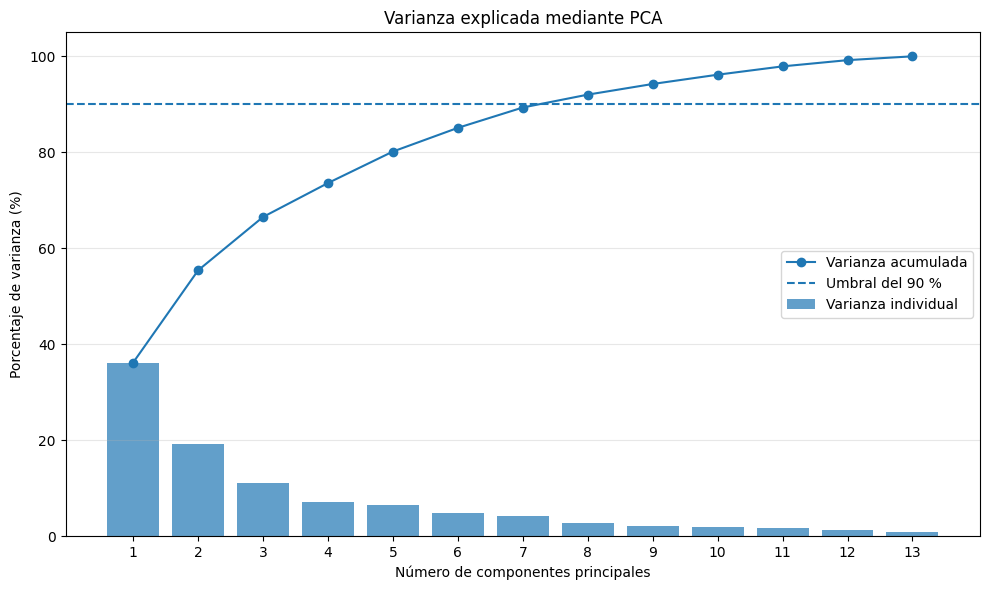

In [ ]:
# PASO 9. Análisis de varianza explicada por PCA

# Aplicar PCA con todos los componentes
pca_completo = PCA()
pca_completo.fit(X_scaled)

# Calcular varianza individual y acumulada
varianza_individual = (
    pca_completo.explained_variance_ratio_
)

varianza_acumulada = np.cumsum(
    varianza_individual
)

# Determinar componentes necesarios para conservar 90 %
componentes_90 = np.searchsorted(
    varianza_acumulada, 0.90
) + 1

# Crear tabla de resultados
tabla_varianza = pd.DataFrame({
    "Componente": range(1, 14),
    "Varianza explicada (%)":
        varianza_individual * 100,
    "Varianza acumulada (%)":
        varianza_acumulada * 100
})

print("Varianza explicada por componente:")
display(tabla_varianza.round(2))

print(
    "\nComponentes necesarios para conservar"
    " al menos el 90 % de la varianza:",
    componentes_90
)

# Graficar varianza explicada y acumulada
plt.figure(figsize=(10, 6))

plt.bar(
    range(1, 14),
    varianza_individual * 100,
    alpha=0.7,
    label="Varianza individual"
)

plt.plot(
    range(1, 14),
    varianza_acumulada * 100,
    marker="o",
    label="Varianza acumulada"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="Umbral del 90 %"
)

plt.title("Varianza explicada mediante PCA")
plt.xlabel("Número de componentes principales")
plt.ylabel("Porcentaje de varianza (%)")
plt.xticks(range(1, 14))
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "paso9_varianza_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


PASO 10. Reducción de dimensionalidad mediante SVD
La descomposición en valores singulares (SVD) es una técnica matemática que permite descomponer una matriz en componentes que representan su estructura. Una de sus aplicaciones es reducir la cantidad de dimensiones de un conjunto de datos, conservando parte de la información original.

En este ejercicio se utilizará TruncatedSVD de Scikit-learn para reducir las 13 características estandarizadas del conjunto Wine a dos componentes. Posteriormente, se calculará el porcentaje de varianza explicada y se representarán los datos en una gráfica.

Como los datos fueron estandarizados previamente, sus variables tienen una media cercana a cero. Esto permitirá comparar los resultados de SVD con los obtenidos mediante PCA, teniendo en cuenta que ambas técnicas están relacionadas matemáticamente, aunque sus procedimientos de implementación presentan diferencias.

Dimensiones originales: (178, 13)
Dimensiones después de SVD: (178, 2)

Primeros cinco registros transformados:


,Componente SVD 1,Componente SVD 2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831



Varianza explicada por componente (%):
[36.2  19.21]

Varianza total conservada con SVD:
55.41 %


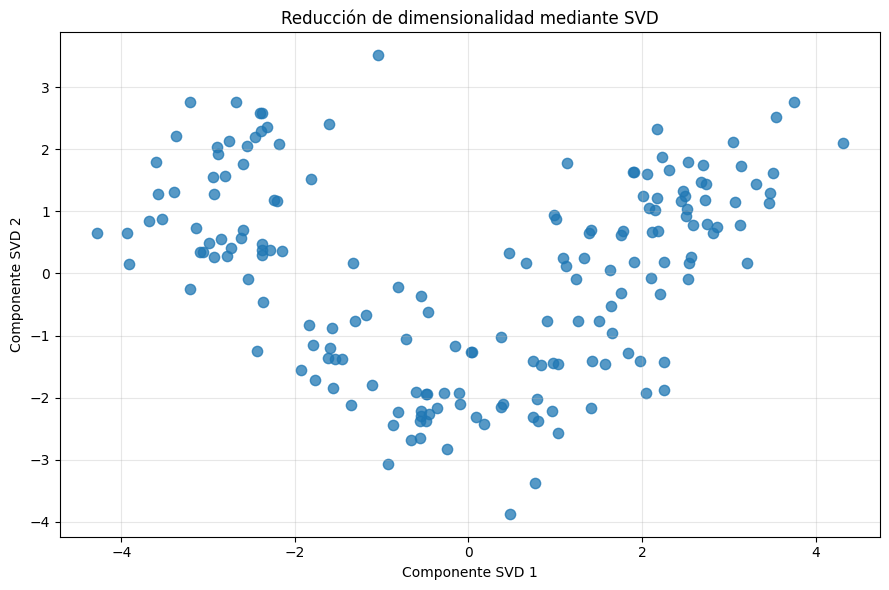

In [ ]:
# PASO 10. Reducción de dimensionalidad mediante SVD

# Aplicar SVD con dos componentes
svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_svd = svd.fit_transform(X_scaled)

# Crear DataFrame con los resultados
df_svd = pd.DataFrame(
    X_svd,
    columns=["Componente SVD 1", "Componente SVD 2"]
)

print("Dimensiones originales:", X_scaled.shape)
print("Dimensiones después de SVD:", X_svd.shape)

print("\nPrimeros cinco registros transformados:")
display(df_svd.head())

# Calcular varianza explicada
varianza_svd = svd.explained_variance_ratio_

print("\nVarianza explicada por componente (%):")
print(np.round(varianza_svd * 100, 2))

print("\nVarianza total conservada con SVD:")
print(round(sum(varianza_svd) * 100, 2), "%")

# Visualizar los datos reducidos
plt.figure(figsize=(9, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    s=55,
    alpha=0.75
)

plt.title("Reducción de dimensionalidad mediante SVD")
plt.xlabel("Componente SVD 1")
plt.ylabel("Componente SVD 2")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "paso10_svd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PASO 11. Comparación de resultados entre PCA y SVD
Después de aplicar PCA y SVD al conjunto de datos Wine, se realizará una comparación para identificar qué porcentaje de la varianza original conserva cada técnica al reducir las 13 características a dos dimensiones.

En los ejercicios anteriores se observó que ambas técnicas conservaron aproximadamente el 55,41 % de la varianza. Esta similitud se relaciona con el hecho de que los datos fueron estandarizados previamente y que PCA y SVD tienen una relación matemática directa cuando se trabaja con matrices centradas.

Para facilitar la comparación, se elaborará una gráfica de barras con los porcentajes obtenidos. Aunque los resultados sean similares, es importante reconocer que PCA busca componentes que expliquen la mayor varianza posible, mientras que SVD descompone una matriz en valores y vectores singulares.

Este análisis permitirá comprender que ambas técnicas pueden ser útiles para reducir dimensiones, pero que su elección depende de las características de los datos y del objetivo del análisis.

Comparación de PCA y SVD:


,Técnica,Dimensiones originales,Dimensiones reducidas,Varianza conservada (%)
0,PCA,13,2,55.41
1,SVD,13,2,55.41


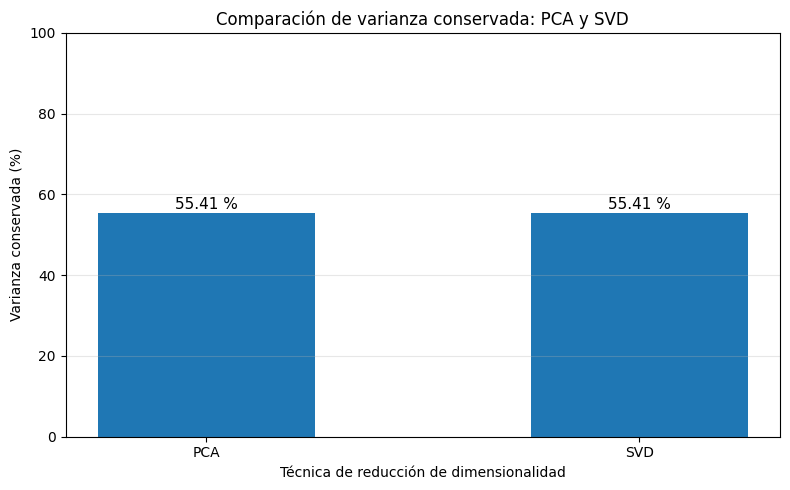


Diferencia entre ambas técnicas: 0.0 puntos porcentuales


In [ ]:
# PASO 11. Comparación entre PCA y SVD

# Calcular la varianza total conservada
varianza_total_pca = sum(
    pca.explained_variance_ratio_
) * 100

varianza_total_svd = sum(
    svd.explained_variance_ratio_
) * 100

# Crear tabla comparativa
comparacion_dimensiones = pd.DataFrame({
    "Técnica": ["PCA", "SVD"],
    "Dimensiones originales": [13, 13],
    "Dimensiones reducidas": [2, 2],
    "Varianza conservada (%)": [
        varianza_total_pca,
        varianza_total_svd
    ]
})

print("Comparación de PCA y SVD:")
display(comparacion_dimensiones.round(2))

# Crear gráfica de barras
plt.figure(figsize=(8, 5))

tecnicas = ["PCA", "SVD"]
porcentajes = [
    varianza_total_pca,
    varianza_total_svd
]

barras = plt.bar(
    tecnicas,
    porcentajes,
    width=0.5
)

# Mostrar porcentajes sobre las barras
for barra, porcentaje in zip(barras, porcentajes):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f} %",
        ha="center",
        fontsize=11
    )

plt.title("Comparación de varianza conservada: PCA y SVD")
plt.ylabel("Varianza conservada (%)")
plt.xlabel("Técnica de reducción de dimensionalidad")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "paso11_comparacion_pca_svd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nDiferencia entre ambas técnicas:",
    round(
        abs(varianza_total_pca - varianza_total_svd),
        6
    ),
    "puntos porcentuales"
)

PASO 12. Análisis general y conclusiones
En este último paso se reúnen los resultados obtenidos mediante K-means, clustering jerárquico, PCA y SVD. El propósito es comparar las técnicas de agrupamiento y reducción de dimensionalidad, teniendo en cuenta las métricas calculadas durante el ejercicio.

Los algoritmos de clustering permitieron identificar grupos de vinos a partir de sus características químicas, mientras que PCA y SVD facilitaron representar los datos utilizando menos dimensiones.

Para finalizar, se presenta un resumen de los resultados y se revisan las principales diferencias entre las técnicas aplicadas. Las conclusiones se fundamentarán en los valores obtenidos y en las limitaciones observadas durante el análisis.

In [ ]:
# PASO 12. Resumen general de resultados

print("RESULTADOS DEL APRENDIZAJE NO SUPERVISADO")
print("=" * 48)

print("\n1. CONJUNTO DE DATOS")
print("Muestras:", X_scaled.shape[0])
print("Características:", X_scaled.shape[1])

print("\n2. ALGORITMOS DE AGRUPAMIENTO")
print("Grupos seleccionados: 3")
print("Silueta K-means:", round(silueta_kmeans, 4))
print("Silueta jerárquico:", round(silueta_jerarquico, 4))

print("\n3. REDUCCIÓN DE DIMENSIONALIDAD")
print("Varianza PCA:", round(varianza_total_pca, 2), "%")
print("Varianza SVD:", round(varianza_total_svd, 2), "%")
print("Componentes para conservar 90 %:", componentes_90)

print("\n4. COMPARACIÓN DE RESULTADOS")

if silueta_kmeans > silueta_jerarquico:
    print("K-means obtuvo mayor coeficiente de silueta.")
elif silueta_kmeans < silueta_jerarquico:
    print("El clustering jerárquico obtuvo mayor silueta.")
else:
    print("Ambos algoritmos obtuvieron igual silueta.")

print("\n5. CONCLUSIÓN GENERAL")
print(
    "Los algoritmos permitieron identificar agrupaciones "
    "y reducir las dimensiones del conjunto Wine. "
    "Los resultados muestran que la selección de una "
    "técnica depende del objetivo del análisis y de "
    "la información que se necesita conservar."
)

print("\nEJERCICIO FINALIZADO CORRECTAMENTE")

RESULTADOS DEL APRENDIZAJE NO SUPERVISADO

1. CONJUNTO DE DATOS
Muestras: 178
Características: 13

2. ALGORITMOS DE AGRUPAMIENTO
Grupos seleccionados: 3
Silueta K-means: 0.2849
Silueta jerárquico: 0.2774

3. REDUCCIÓN DE DIMENSIONALIDAD
Varianza PCA: 55.41 %
Varianza SVD: 55.41 %
Componentes para conservar 90 %: 8

4. COMPARACIÓN DE RESULTADOS
K-means obtuvo mayor coeficiente de silueta.

5. CONCLUSIÓN GENERAL
Los algoritmos permitieron identificar agrupaciones y reducir las dimensiones del conjunto Wine. Los resultados muestran que la selección de una técnica depende del objetivo del análisis y de la información que se necesita conservar.

EJERCICIO FINALIZADO CORRECTAMENTE
